# Análisis de resultados del pipeline EDA

Este notebook lee los CSV de `results/bench/` (generados por `bench/run_benchmarks.py`) y el resumen de la corrida del pipeline (`results/demo/summary_10M.json`), y reproduce las tablas y figuras del informe.

In [1]:
import json, os, sys
import pandas as pd
from IPython.display import Image, display
ROOT = os.path.abspath('..')
RES = os.path.join(ROOT, 'results', 'bench')
sys.path.insert(0, os.path.join(ROOT, 'bench'))
pd.set_option('display.max_columns', 40)

## Plataforma y protocolo

In [2]:
print(json.load(open(os.path.join(RES, 'platform.json'))))

{'python': '3.13.16', 'numpy': '2.5.4', 'platform': 'Linux-6.18.44-fc-v153-x86_64-with-glibc2.39', 'processor': 'x86_64', 'cpus': 4, 'seed': 2026, 'reps': {'1000': 100, '10000': 100, '100000': 10, '1000000': 3, '10000000': 1}, 'memory_kb': 16477348}


## Figuras log-log y pendientes empíricas

`plots.py` ajusta t ~ n^b en escala log-log; b se compara con la complejidad esperada.


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/sebastiangarcia/.cache/fontconfig
	/Users/sebastiangarcia/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/sebastiangarcia/.cache/fontconfig
	/Users/sebastiangarcia/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/sebastiangarcia/.cache/fontconfig
	/Users/sebastiangarcia/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/sebastiangarcia/.cache/fontconfig
	/Users/sebastiangarcia/.fontconfig


Matplotlib is building the font cache; this may take a moment.


figura: fig_base_scaling.png


figura: fig_bloom.png


figura: fig_cms.png


figura: fig_minhash.png


figura: fig_ann.png


figura: fig_graph.png
             Estructura              Operación  Pendiente             Esperado
            LinkedQueue        enqueue+dequeue       1.12                 O(n)
              MergeSort                   sort       1.21           O(n log n)
             BinaryHeap               push+pop       1.22           O(n log n)
              HashTable                put+get       1.08                 O(n)
               LRUCache                get/put       0.94                 O(n)
              BPlusTree              bulk_load       0.89    O(n) / O(n log n)
              BPlusTree                 insert       1.36    O(n) / O(n log n)
                 KDTree   knn10(100 consultas)       0.11     O(log n) vs O(n)
       KNN fuerza bruta   knn10(100 consultas)       1.02     O(log n) vs O(n)
              BPlusTree  search (por consulta)       0.32       O(log_B n) ≈ 0
            BloomFilter   insert+query (vect.)       1.09               O(n·k)
         CountMinSketch       

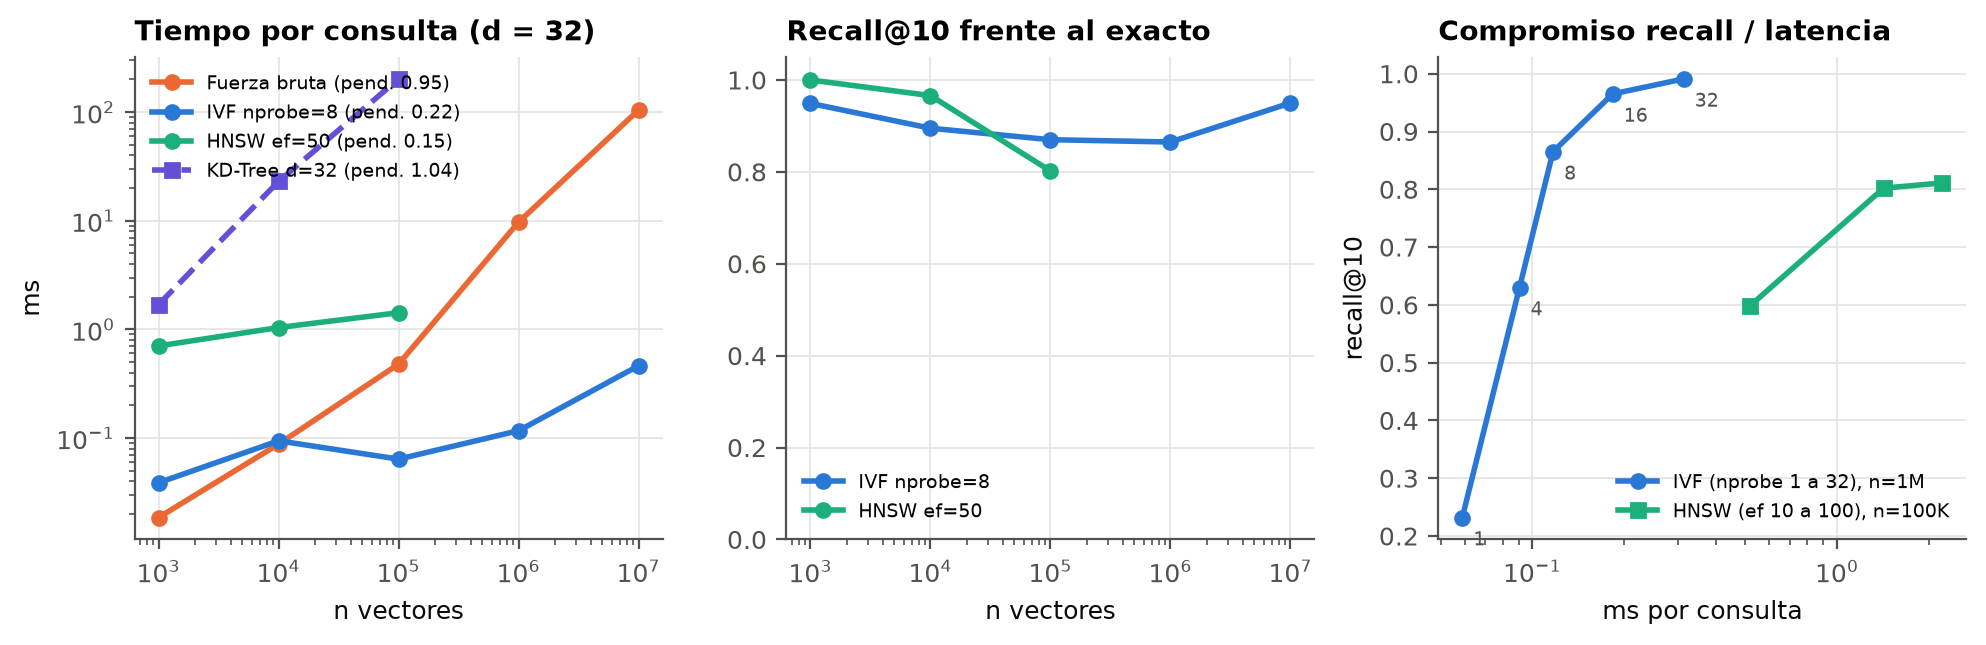

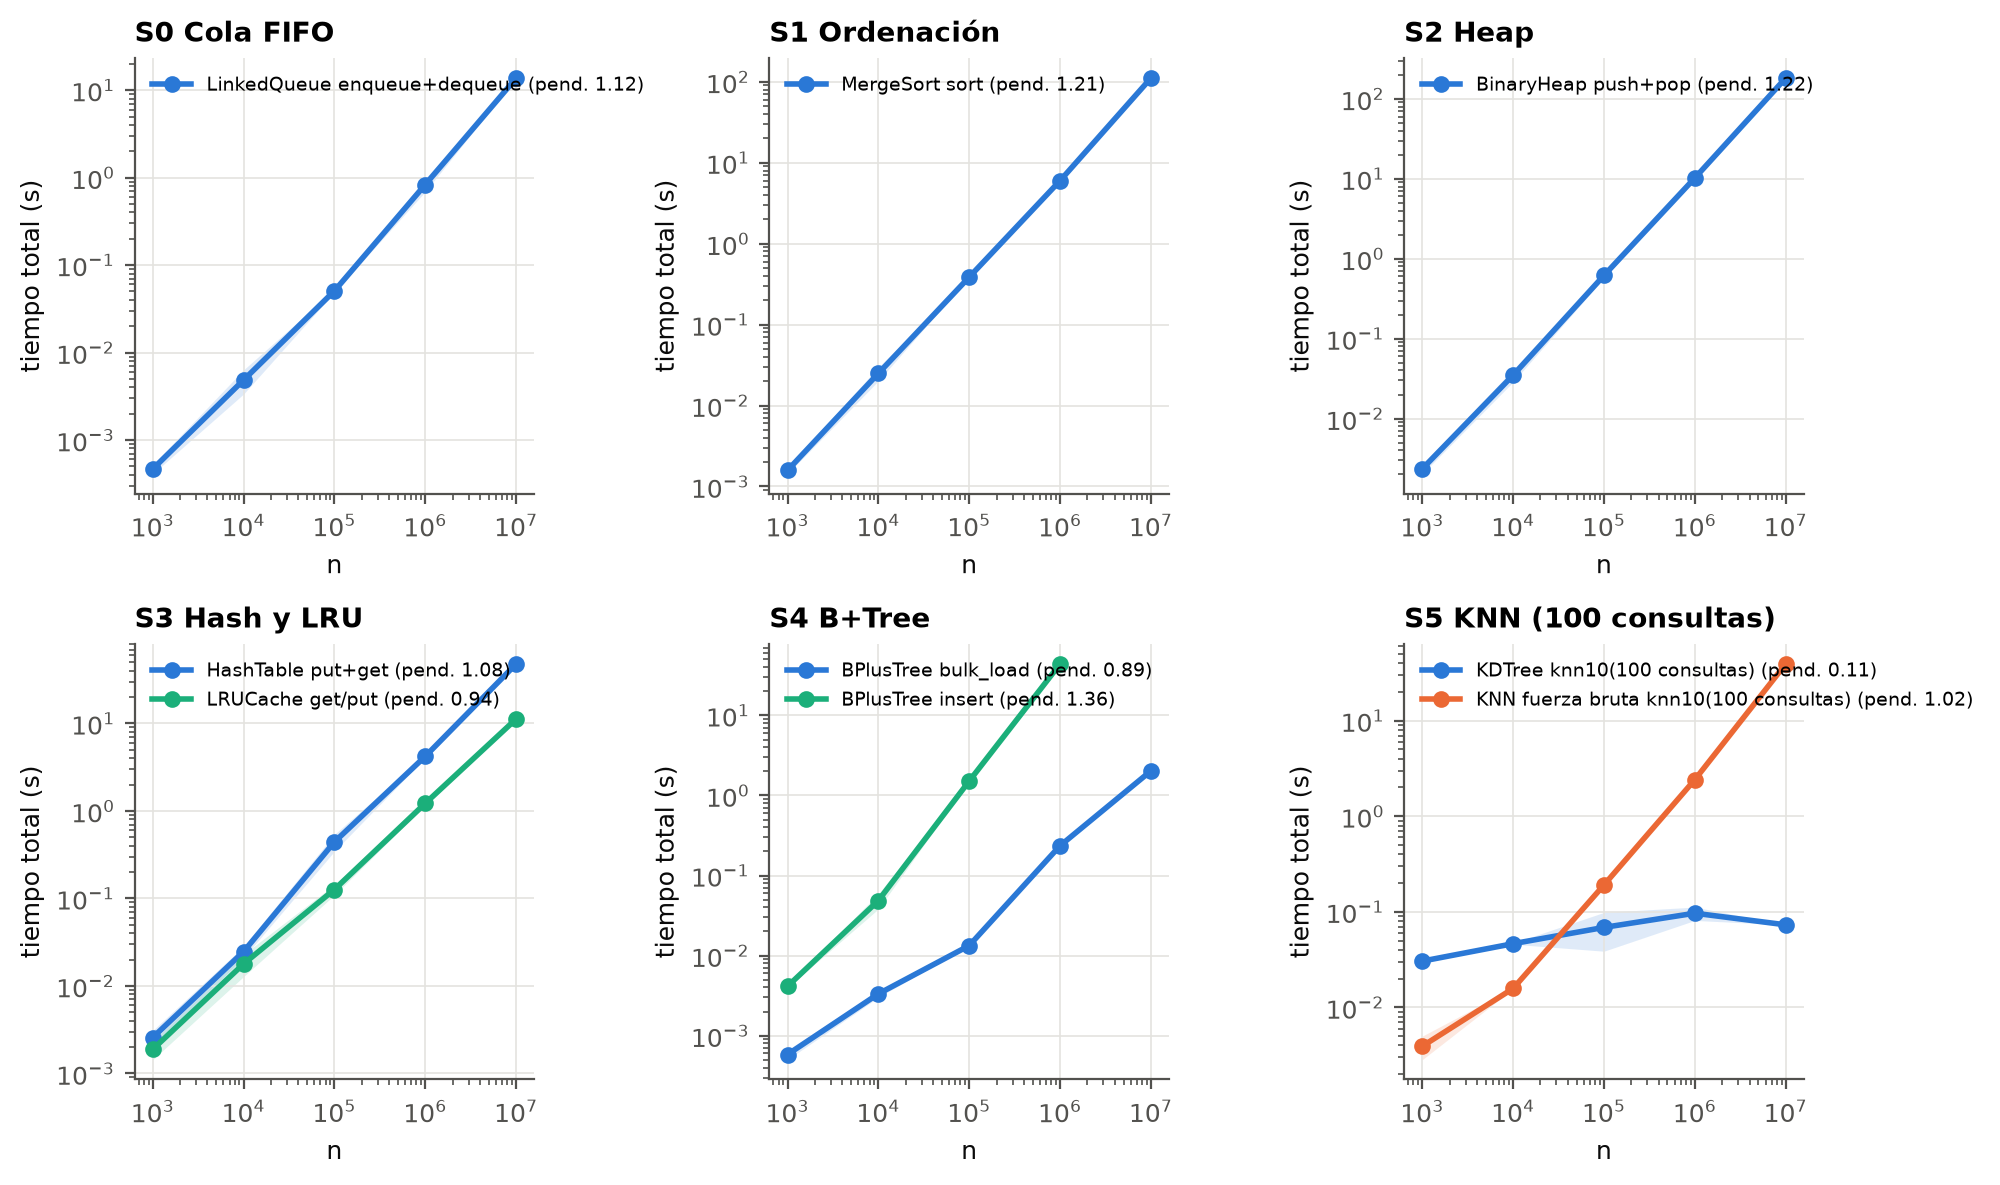

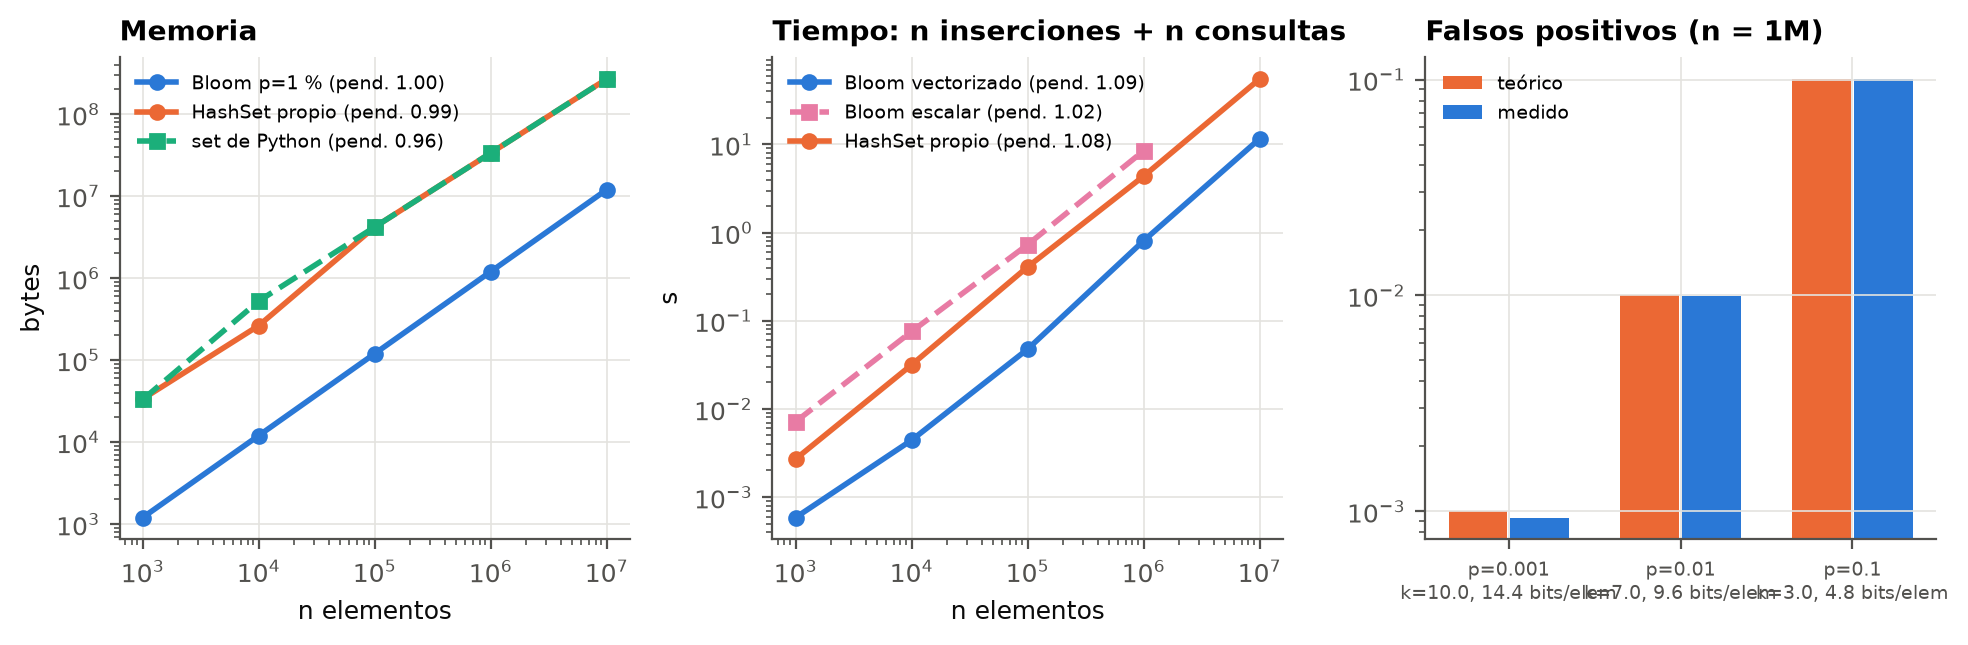

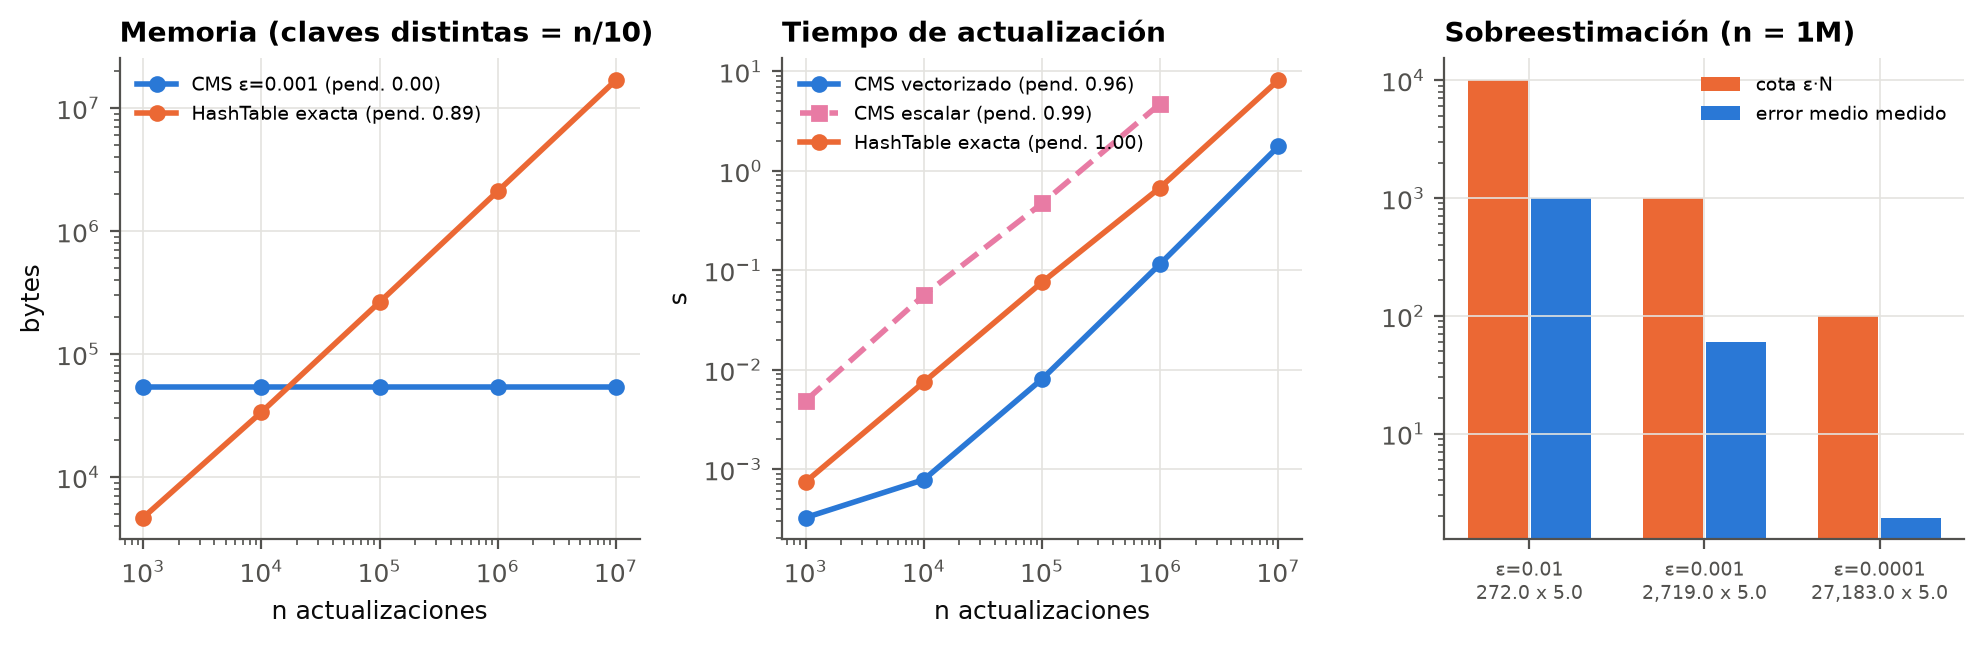

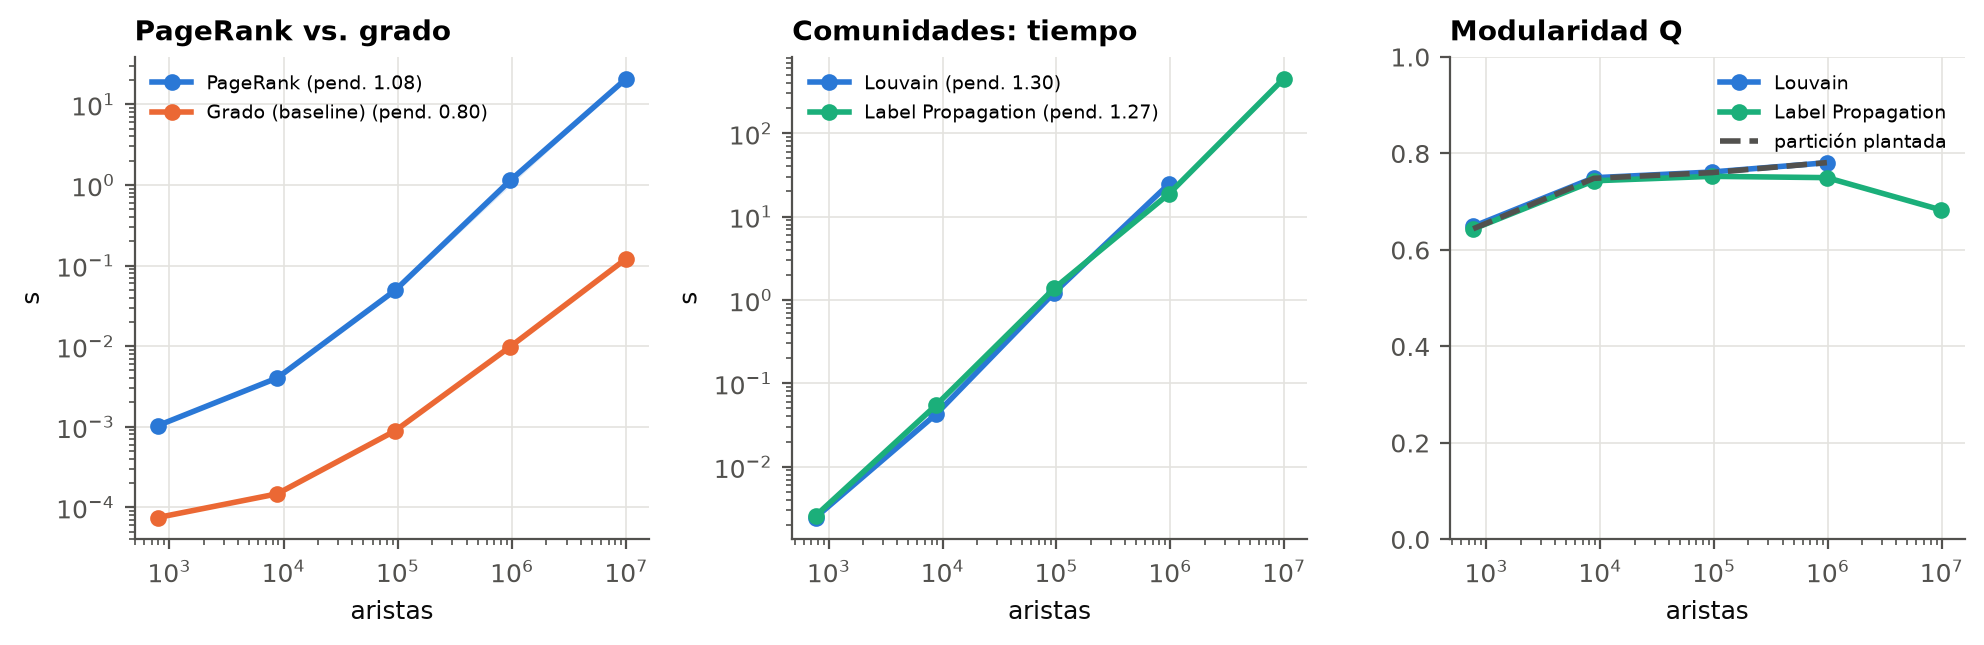

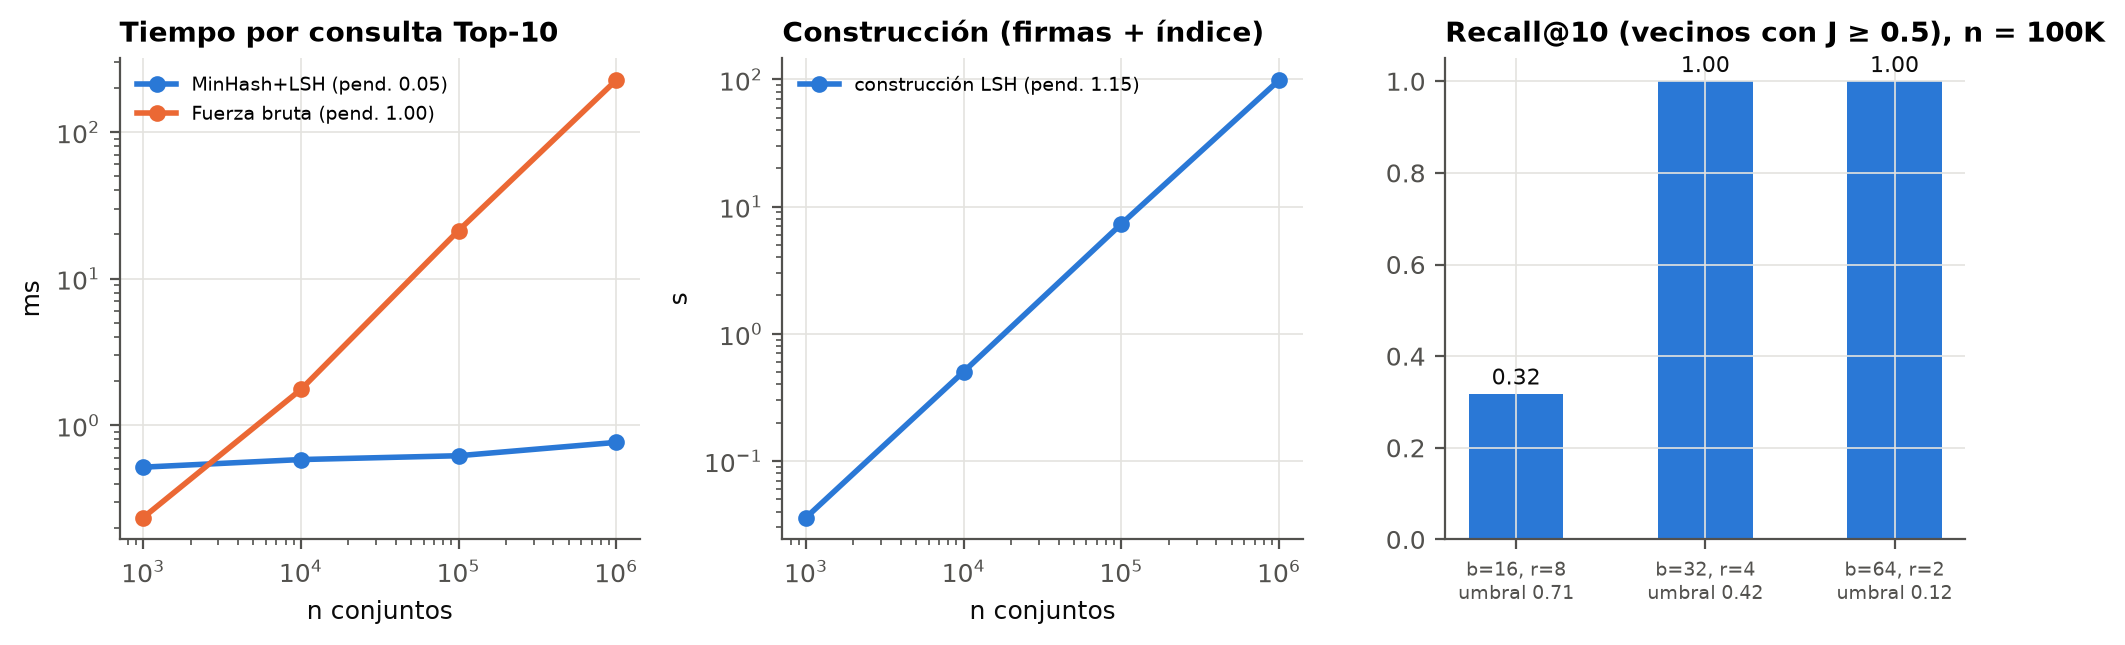

In [3]:
import plots
plots.main()
for f in sorted(os.listdir(plots.FIG)):
    if f.startswith('fig_'):
        display(Image(os.path.join(plots.FIG, f)))

## Tablas por experimento

In [4]:
for name in ['base_structures','bloom_vs_exact','cms_vs_exact','minhash_vs_bruteforce','ann_vs_exact','pagerank_vs_degree','communities']:
    p = os.path.join(RES, name + '.csv')
    if os.path.exists(p):
        print('=' * 10, name)
        display(pd.read_csv(p))

========== base_structures


,structure,op,n,reps,mean_s,std_s,per_op_us,mem_current_B,mem_peak_B,expected,extra
0,LinkedQueue,enqueue+dequeue,1000,100,0.000465,0.000055,0.232708,48152.0,48232.0,O(1),NaN
1,MergeSort,sort,1000,100,0.001580,0.000148,1.580477,NaN,NaN,O(n log n),NaN
2,BinaryHeap,push+pop,1000,100,0.002357,0.000317,1.178308,NaN,NaN,O(log n),NaN
3,HashTable,put+get,1000,100,0.002573,0.000524,1.286450,33480.0,50200.0,O(1),probes_per_op=2.124
4,LRUCache,get/put,1000,100,0.001885,0.000448,1.884929,NaN,NaN,O(1),hit_rate=0.603
5,BPlusTree,bulk_load,1000,20,0.000581,0.000080,0.581087,NaN,NaN,O(n),NaN
6,BPlusTree,search(1000),1000,20,0.002902,0.000112,2.901845,NaN,NaN,O(log_B n),height=2;pages=7;file_MB=0.0
7,BPlusTree,range(0.1%),1000,20,0.000020,0.000004,19.620200,NaN,NaN,O(log_B n + k/B),NaN
8,BPlusTree,insert,1000,10,0.004130,0.000150,4.129547,NaN,NaN,O(log_B n),NaN
9,KDTree,build,1000,20,0.002117,0.000145,2.117424,31092.0,NaN,O(n log n),NaN


========== bloom_vs_exact


,structure,p,n,reps,insert_s,insert_std,query_s,query_std,insert_us_op,query_us_op,memory_B,mem_peak_B,fp_rate,fp_theoretical,k,bits_per_item,false_negatives
0,BloomFilter,0.010,1000,100,0.000336,0.000090,0.000250,0.000050,0.336067,0.249754,1199,226503.0,0.010000,0.010035,7.0,9.586000,0.0
1,BloomFilter (escalar),0.010,1000,100,0.004280,0.000444,0.002878,0.000398,4.279721,2.878456,1199,NaN,0.010000,NaN,NaN,NaN,NaN
2,HashSet exacto,0.000,1000,100,0.002034,0.000447,0.000667,0.000048,2.034180,0.667209,33568,50320.0,0.000000,NaN,NaN,NaN,0.0
3,set de Python,0.000,1000,1,NaN,NaN,NaN,NaN,NaN,NaN,32984,41224.0,0.000000,NaN,NaN,NaN,NaN
4,BloomFilter,0.010,10000,100,0.002861,0.000539,0.001563,0.000166,0.286092,0.156274,11982,2253286.0,0.010400,0.010039,7.0,9.585100,0.0
5,BloomFilter (escalar),0.010,10000,100,0.043906,0.007964,0.031638,0.008040,4.390607,3.163780,11982,NaN,0.010400,NaN,NaN,NaN,NaN
6,HashSet exacto,0.000,10000,100,0.023584,0.006855,0.008069,0.001203,2.358368,0.806944,262944,394380.0,0.000000,NaN,NaN,NaN,0.0
7,set de Python,0.000,10000,1,NaN,NaN,NaN,NaN,NaN,NaN,524504,655624.0,0.000000,NaN,NaN,NaN,NaN
8,BloomFilter,0.010,100000,10,0.031821,0.019590,0.015855,0.000290,0.318206,0.158546,119814,22521118.0,0.010310,0.010039,7.0,9.585060,0.0
9,BloomFilter (escalar),0.010,100000,10,0.446704,0.014663,0.284021,0.000293,4.467041,2.840207,119814,NaN,0.010350,NaN,NaN,NaN,NaN


========== cms_vs_exact


...

,method,n,d,build_s,query_ms,recall_at10,memory_B,nlist,nprobe,speedup,ef,M,dist_evals
0,Fuerza bruta (exacto),1000,32,0.000000,0.018558,1.000,128000,NaN,NaN,NaN,NaN,NaN,NaN
1,IVF,1000,32,0.051130,0.038784,0.949,153144,126.0,8.0,0.478497,NaN,NaN,NaN
2,IVF,1000,32,0.051130,0.056315,0.999,153144,126.0,16.0,0.329545,NaN,NaN,NaN
3,"KD-Tree (exacto, d=32)",1000,32,0.002292,1.692004,1.000,147556,NaN,NaN,0.010968,NaN,NaN,NaN
4,HNSW,1000,32,2.165066,0.704224,1.000,339640,NaN,NaN,0.026353,50.0,16.0,208.38
5,Fuerza bruta (exacto),10000,32,0.000000,0.087910,1.000,1280000,NaN,NaN,NaN,NaN,NaN,NaN
6,IVF,10000,32,0.822931,0.094231,0.895,1414408,400.0,8.0,0.932923,NaN,NaN,NaN
7,IVF,10000,32,0.822931,0.137532,0.989,1414408,400.0,16.0,0.639196,NaN,NaN,NaN
8,"KD-Tree (exacto, d=32)",10000,32,0.069753,22.990475,1.000,1470556,NaN,NaN,0.003824,NaN,NaN,NaN
9,HNSW,10000,32,24.807118,1.039405,0.966,3379656,NaN,NaN,0.084577,50.0,16.0,433.03


========== pagerank_vs_degree


,method,edges,nodes,reps,time_s,std_s,iterations,spearman_vs_degree,top100_overlap,memory_B
0,PageRank,794,200,10,0.001032,0.000029,56,0.990938,0.97,27016.0
1,Grado ponderado,794,200,10,0.000075,0.000009,1,NaN,NaN,NaN
2,PageRank,8774,2000,10,0.004019,0.000070,53,0.987226,0.96,296776.0
3,Grado ponderado,8774,2000,10,0.000147,0.000009,1,NaN,NaN,NaN
4,PageRank,94669,20000,10,0.049223,0.002674,50,0.990095,0.96,3189416.0
5,Grado ponderado,94669,20000,10,0.000889,0.000283,1,NaN,NaN,NaN
6,PageRank,961928,200000,3,1.135142,0.154090,49,0.990229,0.97,32381704.0
7,Grado ponderado,961928,200000,3,0.009822,0.000048,1,NaN,NaN,NaN
8,PageRank,9910436,2000000,1,20.677963,0.000000,47,0.991258,0.98,333133960.0
9,Grado ponderado,9910436,2000000,1,0.120715,0.000000,1,NaN,NaN,NaN


========== communities


,method,edges,nodes,runs,time_s,std_s,modularity,modularity_truth,n_communities,largest,median_size,singletons,stability_nmi,nmi_vs_truth
0,Louvain,765,200,5,0.002451,0.000318,0.648776,0.643896,8,46,23.0,1,0.989063,0.935588
1,Label Propagation,765,200,5,0.002562,0.000521,0.643361,0.643896,10,42,19.5,1,0.909281,0.903510
2,Louvain,8787,2000,5,0.042711,0.003523,0.749697,0.748498,26,334,61.0,4,0.987338,0.947724
3,Label Propagation,8787,2000,5,0.054876,0.011605,0.743411,0.748498,37,348,34.0,4,0.961488,0.948819
4,Louvain,95767,20000,5,1.223999,0.181848,0.761617,0.760372,91,3677,154.0,22,0.994784,0.965996
5,Label Propagation,95767,20000,5,1.377764,0.174951,0.752636,0.760372,127,3752,123.0,22,0.969802,0.962222
6,Louvain,980038,200000,5,24.820945,6.264859,0.780916,0.781039,436,20541,1.0,219,0.993360,0.964754
7,Label Propagation,980038,200000,5,18.880582,1.085993,0.749925,0.781039,704,45854,2.0,219,0.942411,0.934483
8,Label Propagation,9880088,2000000,1,447.966101,0.000000,0.682944,0.796795,104606,14659,3.0,2295,NaN,0.867946


## Corrida del pipeline con 10M eventos

In [5]:
p = os.path.join(ROOT, 'results', 'demo', 'summary_10M.json')
if os.path.exists(p):
    s = json.load(open(p, encoding='utf-8'))
    display(pd.Series({k: s[k] for k in ['eventos_recibidos','segundos','eventos_por_segundo']}))
    display(pd.DataFrame(s['tiempos_por_etapa_s'], index=['s']).T)
    print('\n'.join(s['traza_evento']['pasos']))
    display(pd.DataFrame(s['traza_evento']['recomendaciones']))

eventos_recibidos      10223169.00
segundos                   1246.18
eventos_por_segundo        8204.00
dtype: float64

,s
setup,2.754
S0 ingesta,258.545
S1 preprocesamiento,69.493
S2 prioridad,78.597
S3 almacenamiento,37.972
S6 filtrado,50.259
S3 interacciones,45.880
S4 B+Tree,3.800
S5 KD-Tree,0.432
S7 similitud,0.216


[S0] encolado (cola=1413)
[S1] válido, normalizado y no duplicado
[S2] prioridad 3 (compra programada), posición 133 de 4929 en el lote
[S3] producto #861 y usuario #746718 resueltos en la tabla hash
[S6] pasa el filtro (Bloom: ausente; CMS bajo el umbral)
[S4] orden indexada por tiempo en el B+Tree
[S5] vecinos por atributos (KD-Tree): [786, 840, 14608]
[S7] relacionados LSH: []; vecinos IVF: [87190, 87862, 40728]
[S8] primera compra de la orden: nodo listo para nuevas aristas


,idx,product_id,name,brand,category,price,views,purchases,puntaje,fuentes
0,786,1004767,samsung smartphone 4767,samsung,electronics.smartphone,252.63,82294,4872,1.689,grafo+KD-Tree
1,840,1004833,samsung smartphone 4833,samsung,electronics.smartphone,173.98,42043,2788,1.448,grafo+KD-Tree
2,776,1004750,samsung smartphone 4750,samsung,electronics.smartphone,197.77,28199,1246,1.024,grafo
3,87190,26018289,generic unknown 8289,generic,unknown,6.56,1,0,1.001,IVF
4,843,1004836,samsung smartphone 4836,samsung,electronics.smartphone,230.61,34513,1674,0.954,grafo
